In [ ]:
import torch
import torch.nn as nn
import os
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

from copy import deepcopy

from cmcrameri import cm

In [2]:
from repl.networks.utils import additional_data_process, prepare_model
from repl.scripts.utils import get_data_specs, prepare_data
from repl.networks.networks import LinearReadout

In [ ]:
sprites_savedir = 'RPL_figures/3_latent_simulation'
if not os.path.exists(sprites_savedir):
    os.makedirs(sprites_savedir)

In [ ]:
input_size, num_classes = get_data_specs(dataset="animals",
                                        target_label="multitask",
                                        flatten_images=False,
                                        spritevid_num_sprites=8)

(train_loader, train_sampler, 
    val_loader, val_sampler,
        test_loader, test_sampler,
    ) = prepare_data(
            dataset="animals",
            data_input_dir="../datasets",
            seq_len=32,
            num_workers=0,
            batch_size=128,
            val_batch_size=128,
            grayscale=False,
            target_label="multitask",
            spritevid_max_sprites=8,
            spritevid_noise_type="gaussian",
            spritevid_noise_level=0.1,
            sprite_noise_on_top=True,
            spritevid_discretize_latents=False,
        )

Computing normalization values using 10000 samples...
Computed normalization values - mean: tensor([0.5009, 0.4961, 0.4950], device='cuda:0'), std: tensor([0.1234, 0.1192, 0.1209], device='cuda:0')


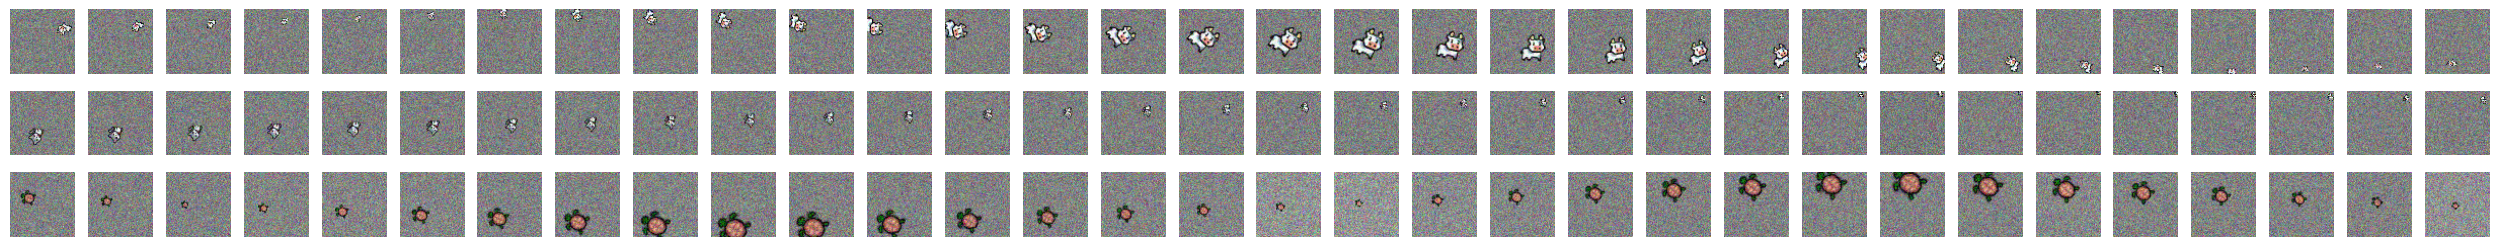

In [ ]:
# show the first 3 videos of 32 frames each (64x64 grayscale images)
data, labels = next(iter(train_loader))

# show images in data_samples (selected 3 samples each a sequence of 16 64x64 images)
samples_to_plot = [2, 4, 8]

data_samples_to_plot = data[samples_to_plot].detach().cpu().numpy()

fig, ax = plt.subplots(3, 32, figsize=(32, 3))

for i in range(len(samples_to_plot)):
    for j in range(32):
        ax[i, j].imshow((data_samples_to_plot[i, j] - data_samples_to_plot[i, j].min()).T / (data_samples_to_plot[i, j].max() - data_samples_to_plot[i, j].min()).T)
        ax[i, j].axis('off')

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
preprocess, postprocess = additional_data_process("dsprites", flatten_enc_output=True)
n_in_channels = 3

pred_model = deepcopy(prepare_model(
    encoder_kind="conv2d",
    integrator_kind="lstm",
    predictor_kind="mlp",
    input_size=input_size,
    n_in_channels=n_in_channels,
    enc_dim=32,
    ctx_dim=512,
    pred_n_hidden_layers=1,
    pred_hidden_dim=512,
    pred_steps=1,
    prediction_target="enc",
    use_bn_enc=True,
    enc_n_layers=6,
    enc_kernel_size=[(5, 5)] * 6,
    enc_stride=[(2, 2)] * 2 + [(1, 1)] * 4,
    enc_padding=[(2, 2)] * 6,
    preprocess=preprocess,
    postprocess=postprocess,
    flatten_enc_output=True,
    return_full_features=True,
    state_dict=torch.load("../checkpoints/animals_cts_noiseOnTop0.1_pred_1/model_final.pt"),
)).to(device)

In [8]:
def prepare_readout(readout_input_dim, num_classes):
    readout = nn.ModuleList()
    num_classes_seq_labels = num_classes[0]
    if num_classes_seq_labels is not None:
        for task_name in num_classes_seq_labels.keys():
            readout.append(LinearReadout(num_classes=num_classes_seq_labels[task_name], input_dim=readout_input_dim,
                                            seq_len=16, concat_over_time=False, task_name=task_name,
                                            concat_over_batch=False))
    num_classes_dense_labels = num_classes[1]
    if num_classes_dense_labels is not None:
        for task_name in num_classes_dense_labels.keys():
            readout.append(LinearReadout(num_classes=num_classes_dense_labels[task_name], input_dim=readout_input_dim,
                                            seq_len=16, concat_over_time=False, task_name=task_name,
                                            concat_over_batch=True))
    num_seq_regr_targets = num_classes[2]
    if num_seq_regr_targets is not None:
        for task_name in num_seq_regr_targets.keys():
            readout.append(LinearReadout(num_classes=num_seq_regr_targets[task_name], input_dim=readout_input_dim,
                                            seq_len=16, concat_over_time=False, task_name=task_name,
                                            concat_over_batch=False))
    num_dense_regr_targets = num_classes[3]
    if num_dense_regr_targets is not None:
        for task_name in num_dense_regr_targets.keys():
            readout.append(LinearReadout(num_classes=num_dense_regr_targets[task_name], input_dim=readout_input_dim,
                                            seq_len=16, concat_over_time=False, task_name=task_name,
                                            concat_over_batch=True))
    
    return readout

In [ ]:
readout_input_dim = pred_model.integrator.backbone.weight_ih_l0.shape[0] // 4

pred_readout = prepare_readout(readout_input_dim, num_classes=num_classes).to(device)

In [ ]:
pred_readout.load_state_dict(torch.load('../checkpoints/animals_cts_noiseOnTop0.1_pred_1/offline_ctx_readout.pt'))
pred_readout_stats = torch.load('../checkpoints/animals_cts_noiseOnTop0.1_pred_1/offline_ctx_readout_stats.pt')

In [ ]:
pred_readout_input_mean_train = pred_readout_stats['mean'].to(device)
pred_readout_input_std_train = pred_readout_stats['std'].to(device)

In [12]:
for readout in pred_readout:
    print(readout.task_name, readout.concat_over_batch, readout.concat_over_time)

sprite_idx False False
rotation_direction False False
x-direction True False
y-direction True False
z-direction True False
x-position (discr) True False
y-position (discr) True False
z-position (discr) True False
orientation True False
speed False False
rotation_speed False False
x-position True False
y-position True False
z-position True False
x-velocity True False
y-velocity True False
z-velocity True False
sin True False
cos True False


In [14]:
from readout_utils import train_corrected_orientation_regressor, extract_data

In [15]:
pred_train_representations, pred_train_gt_orientations_raw, train_sprite_labels_raw, _,_,_ = extract_data(
    pred_model, pred_readout, device, pred_readout_input_mean_train, pred_readout_input_std_train,
    train_loader, num_classes, seq_len=32, repr_dim=512, train_set=True)

In [16]:
pred_train_representations.shape, pred_readout_input_mean_train.shape

(torch.Size([319488, 512]), torch.Size([1, 1, 512]))

In [17]:
pred_train_representations = (pred_train_representations - pred_readout_input_mean_train[0]) / (pred_readout_input_std_train[0] + 1e-8)

In [18]:
pred_train_representations.shape

torch.Size([319488, 512])

In [19]:
pred_corrected_readout = train_corrected_orientation_regressor(
    pred_train_representations, pred_train_gt_orientations_raw, train_sprite_labels_raw,
    learning_rate=0.01, n_epochs=5000, device=device, num_sprite_classes=8, orientation_discr_levels=36
)

Corrected Orientation Training:   0%|          | 0/5000 [00:00<?, ?it/s]

In [24]:
pred_test_representations, pred_test_gt_orientations_raw, test_sprite_labels_raw, _,_,_ = extract_data(
    pred_model, pred_readout, device, pred_readout_input_mean_train, pred_readout_input_std_train,
    test_loader, num_classes, seq_len=32, repr_dim=512, train_set=False)

In [ ]:
from tqdm import tqdm
import torch
from sklearn.metrics import r2_score
from readout_utils import get_corrected_orientation_projections_test

ctx_steps = 8

# Set models to evaluation mode
pred_model.eval()

# Define task types for proper metric calculation
classification_tasks = ['sprite_idx', 'rotation_direction', 'x-direction', 'y-direction', 
                       'z-direction', 'orientation', 'x-position (discr)', 'y-position (discr)',
                       'z-position (discr)']
task_names = [readout.task_name for readout in pred_readout]

pred_sim_representations = []

# Initialize storage for ground truth and predictions
ground_truth = {key: [] for key in task_names}
pred_gt_predictions = {key: [] for key in task_names}
pred_sim_predictions = {key: [] for key in task_names}

# Initialize accuracy metrics
pred_gt_acc = {key: 0.0 for key in task_names}
pred_sim_acc = {key: 0.0 for key in task_names}

# Initialize reconstruction error
pred_reconstruction_error = {key: torch.zeros(32) for key in task_names}

for i, (data, target) in enumerate(tqdm(test_loader)):
    data = data.to(device)
    target = tuple([t.to(device) for t in target])
    
    # Unpack the targets
    seq_labels = target[0]           # [batch_size, 2] - sprite_idx, rotation_dir
    dense_labels = target[1]         # [batch_size, seq_len, 4] - x, y, z, orientation
    cts_labels = target[2]           # [batch_size, 2] - speed, angular_speed
    cts_dense_labels = target[3]     # [batch_size, seq_len, 8] - x, y, z, vx, vy, vz, sin, cos
    aux_labels = target[4]

    with torch.no_grad():
        # Get outputs from both models
        pred_enc, pred_ctx, pred_pred = pred_model(data)
        
        # Initialize simulation outputs with context steps
        pred_sim_outputs = torch.zeros_like(pred_ctx)
        pred_sim_outputs[:, :ctx_steps] = pred_ctx[:, :ctx_steps]
        
        # Initialize simulation inputs
        pred_sim_inputs = torch.zeros_like(pred_enc)
        pred_sim_inputs[:, :ctx_steps] = pred_enc[:, :ctx_steps]
        pred_sim_inputs[:, ctx_steps] = pred_pred[:, ctx_steps-1]
        
        # Get model components
        pred_integrator = pred_model.integrator.backbone
        pred_predictor = pred_model.predictor
        
        # Run simulations
        for t in range(ctx_steps, 32):
            # Predict next step for pred model
            pred_sim_output, _ = pred_integrator(pred_sim_inputs[:, :t+1])
            pred_sim_outputs[:, t] = pred_sim_output[:, -1]
            if t < 31:
                pred_sim_inputs[:, t+1] = pred_predictor(pred_sim_output)[:, -1]
            
        # Normalize outputs
        pred_gt_outputs = (pred_ctx - pred_readout_input_mean_train) / (pred_readout_input_std_train + 1e-8)
        pred_sim_outputs = (pred_sim_outputs - pred_readout_input_mean_train) / (pred_readout_input_std_train + 1e-8)
        
        pred_sim_representations.append(pred_sim_outputs)
        
        # Helper function to get the correct ground truth labels
        def get_ground_truth(task_name):
            if task_name == 'sprite_idx':
                return seq_labels[:, 0]
            elif task_name == 'rotation_direction':
                return seq_labels[:, 1]
            elif task_name == 'x-direction':
                return dense_labels[:, :, 0]
            elif task_name == 'y-direction':
                return dense_labels[:, :, 1]
            elif task_name == 'z-direction':
                return dense_labels[:, :, 2]
            elif task_name == 'x-position (discr)':
                return dense_labels[:, :, 3]
            elif task_name == 'y-position (discr)':
                return dense_labels[:, :, 4]
            elif task_name == 'z-position (discr)':
                return dense_labels[:, :, 5]
            elif task_name == 'orientation':
                return dense_labels[:, :, 6]
            elif task_name == 'speed':
                return cts_labels[:, 0]
            elif task_name == 'rotation_speed':
                return cts_labels[:, 1]
            elif task_name == 'x-position':
                return cts_dense_labels[:, :, 0]
            elif task_name == 'y-position':
                return cts_dense_labels[:, :, 1]
            elif task_name == 'z-position':
                return cts_dense_labels[:, :, 2]
            elif task_name == 'x-velocity':
                return cts_dense_labels[:, :, 3]
            elif task_name == 'y-velocity':
                return cts_dense_labels[:, :, 4]
            elif task_name == 'z-velocity':
                return cts_dense_labels[:, :, 5]
            elif task_name == 'sin':
                return cts_dense_labels[:, :, 6]
            elif task_name == 'cos':
                return cts_dense_labels[:, :, 7]
        
        # Process each task
        for pred_readout_i in pred_readout:
            task_name = pred_readout_i.task_name
            is_classification = task_name in classification_tasks
            is_sequence = task_name not in ['sprite_idx', 'rotation_direction', 'speed', 'rotation_speed']
            
            # Get ground truth
            y = get_ground_truth(task_name)
            
            # Process outputs based on task type
            if is_classification:
                pred_gt_out = pred_readout_i(pred_gt_outputs).argmax(dim=1)
                pred_sim_out = pred_readout_i(pred_sim_outputs).argmax(dim=1)
            else:
                pred_gt_out = pred_readout_i(pred_gt_outputs)
                pred_sim_out = pred_readout_i(pred_sim_outputs)
            
            # Reshape for sequence tasks
            if is_sequence:
                y = y.view(-1, 32)
                if y.dim() != pred_gt_out.dim() or y.size(1) != pred_gt_out.size(1):
                    pred_gt_out = pred_gt_out.view(-1, 32)
                    pred_sim_out = pred_sim_out.view(-1, 32)
            
            # Store for later metric calculation
            ground_truth[task_name].append(y)
            pred_gt_predictions[task_name].append(pred_gt_out)
            pred_sim_predictions[task_name].append(pred_sim_out)

# Concatenate simulation representations
pred_sim_representations = torch.cat(pred_sim_representations, dim=0)

# Concatenate predictions and calculate metrics
for task_name in task_names:
    if not ground_truth[task_name]:
        continue
        
    # Concatenate along batch dimension
    ground_truth[task_name] = torch.cat(ground_truth[task_name], dim=0)
    pred_gt_predictions[task_name] = torch.cat(pred_gt_predictions[task_name], dim=0)
    pred_sim_predictions[task_name] = torch.cat(pred_sim_predictions[task_name], dim=0)
    
    is_classification = task_name in classification_tasks
    is_sequence = task_name not in ['sprite_idx', 'rotation_direction', 'speed', 'rotation_speed']
    
    # Calculate metrics
    if is_sequence:
        for t in range(ctx_steps, 32):
            y_t = ground_truth[task_name][:, t]
            
            # For classification tasks
            if is_classification:
                pred_gt_acc[task_name] += (pred_gt_predictions[task_name][:, t] == y_t).float().mean().item() / (32 - ctx_steps)
                pred_sim_acc[task_name] += (pred_sim_predictions[task_name][:, t] == y_t).float().mean().item() / (32 - ctx_steps)
            # For regression tasks
            else:
                pred_gt_acc[task_name] += r2_score(y_t.cpu().numpy(), pred_gt_predictions[task_name][:, t].cpu().numpy()) / (32 - ctx_steps)
                pred_sim_acc[task_name] += r2_score(y_t.cpu().numpy(), pred_sim_predictions[task_name][:, t].cpu().numpy()) / (32 - ctx_steps)
    else:
        # For non-sequence tasks
        if is_classification:
            pred_gt_acc[task_name] = (pred_gt_predictions[task_name] == ground_truth[task_name]).float().mean().item()
            pred_sim_acc[task_name] = (pred_sim_predictions[task_name] == ground_truth[task_name]).float().mean().item()
        else:
            pred_gt_acc[task_name] = r2_score(ground_truth[task_name].cpu().numpy(), pred_gt_predictions[task_name].cpu().numpy())
            pred_sim_acc[task_name] = r2_score(ground_truth[task_name].cpu().numpy(), pred_sim_predictions[task_name].cpu().numpy())

    # Calculate reconstruction error between ground truth and simulated predictions
    # For sequence tasks, calculate error for each time step
    if is_sequence:
        for t in range(32):
            y_t = ground_truth[task_name][:, t].float()
            pred_sim_t = pred_sim_predictions[task_name][:, t]
            pred_reconstruction_error[task_name][t] = torch.nn.functional.mse_loss(pred_sim_t, y_t)
    else:
        pred_reconstruction_error.pop(task_name)

# Print metrics
print("=== Prediction Model ===")
print("Ground Truth Prediction Accuracy:")
for task_name, acc in pred_gt_acc.items():
    print(f"{task_name}: {acc:.4f}")

print("\nSimulation Prediction Accuracy:")
for task_name, acc in pred_sim_acc.items():
    print(f"{task_name}: {acc:.4f}")

# Calculate and print average metrics
pred_avg_gt = sum(pred_gt_acc.values()) / len(pred_gt_acc)
pred_avg_sim = sum(pred_sim_acc.values()) / len(pred_sim_acc)

print("\n=== Summary ===")
print(f"Pred model - GT avg: {pred_avg_gt:.4f}, Sim avg: {pred_avg_sim:.4f}")

100%|██████████| 31/31 [00:27<00:00,  1.12it/s]


=== Prediction Model ===
Ground Truth Prediction Accuracy:
sprite_idx: 1.0000
rotation_direction: 0.9546
x-direction: 0.9710
y-direction: 0.9691
z-direction: 0.9586
x-position (discr): 0.8355
y-position (discr): 0.8288
z-position (discr): 0.7022
orientation: 0.2129
speed: 0.9611
rotation_speed: 0.9672
x-position: 0.9943
y-position: 0.9947
z-position: 0.9860
x-velocity: 0.9103
y-velocity: 0.9065
z-velocity: 0.8651
sin: 0.6013
cos: 0.6120

Simulation Prediction Accuracy:
sprite_idx: 0.9987
rotation_direction: 0.8707
x-direction: 0.9088
y-direction: 0.8986
z-direction: 0.7993
x-position (discr): 0.3186
y-position (discr): 0.2946
z-position (discr): 0.2229
orientation: 0.0833
speed: 0.9457
rotation_speed: 0.7136
x-position: 0.9029
y-position: 0.8743
z-position: 0.4621
x-velocity: 0.7726
y-velocity: 0.7523
z-velocity: 0.4354
sin: 0.2020
cos: 0.1882

=== Invariance Model ===
Ground Truth Prediction Accuracy:
sprite_idx: 1.0000
rotation_direction: 0.5658
x-direction: 0.6480
y-direction: 0.648

In [28]:
corrected_orientation_proj_pred = get_corrected_orientation_projections_test(
    pred_sim_representations, pred_test_gt_orientations_raw, test_sprite_labels_raw,
    *pred_corrected_readout)

In [29]:
corrected_orientation_proj_pred[0].shape, corrected_orientation_proj_pred[2].shape

((3968, 32, 2), (126976, 1))

In [30]:
pred_corrected_orientation_cts, pred_corrected_orientation_dscrt, pred_sin_true, pred_cos_true, pred_theta_dscrt = corrected_orientation_proj_pred
pred_corrected_orientation_cts.shape

(3968, 32, 2)

In [31]:
pred_corrected_orientation_cts.shape, pred_sin_true.shape

((3968, 32, 2), (126976, 1))

In [32]:
pred_sin_true = pred_sin_true.reshape((-1, 32))
pred_cos_true = pred_cos_true.reshape((-1, 32))

In [33]:
mse_pred_sin = torch.zeros(32)
mse_pred_cos = torch.zeros(32)

In [34]:
pred_corrected_orientation_cts = torch.tensor(pred_corrected_orientation_cts)
pred_sin_true = torch.tensor(pred_sin_true)
pred_cos_true = torch.tensor(pred_cos_true)

In [35]:
r2_score(pred_sin_true.flatten(), pred_corrected_orientation_cts[:,:, 0].flatten(0,1))

0.39706233433162763

In [36]:
for i in range(32):
    mse_pred_sin[i] = torch.nn.functional.mse_loss(pred_corrected_orientation_cts[:, i, 0], pred_sin_true[:, i])
    mse_pred_cos[i] = torch.nn.functional.mse_loss(pred_corrected_orientation_cts[:, i, 1], pred_cos_true[:, i])
mse_pred_sin, mse_pred_cos

(tensor([0.1546, 0.1088, 0.1084, 0.1081, 0.1045, 0.1068, 0.1067, 0.1055, 0.1169,
         0.1352, 0.1544, 0.1699, 0.1871, 0.2036, 0.2230, 0.2447, 0.2727, 0.2983,
         0.3185, 0.3496, 0.3714, 0.3899, 0.4173, 0.4439, 0.4722, 0.5050, 0.5260,
         0.5451, 0.5595, 0.5728, 0.5924, 0.6220]),
 tensor([0.1762, 0.1162, 0.1125, 0.1074, 0.1061, 0.1054, 0.1050, 0.1066, 0.1208,
         0.1369, 0.1536, 0.1699, 0.1895, 0.2079, 0.2283, 0.2491, 0.2645, 0.2798,
         0.3033, 0.3268, 0.3500, 0.3768, 0.4006, 0.4249, 0.4511, 0.4792, 0.5093,
         0.5341, 0.5621, 0.5866, 0.5974, 0.6085]))

In [37]:
import matplotlib as mpl
# Configure matplotlib to use LaTeX for r'' strings while keeping other text unchanged
mpl.rcParams.update({
    'text.usetex': True,          # Use LaTeX for r'' strings
    'font.family': 'sans-serif',  # Default font family for regular text
    'mathtext.fontset': 'dejavusans',  # Font for math not using r''
    'axes.formatter.use_mathtext': True  # Enable math text for tick labels
})

In [38]:
pred_gt_outputs.shape

torch.Size([128, 32, 512])

# Error plot

In [39]:
import matplotlib
matplotlib.rc('text', usetex=True)
matplotlib.rc('text.latex', preamble=r'\usepackage{amsmath}')

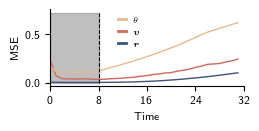

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(2.5, 1.0))
t = torch.arange(32)
color1 = cm.lipari(0.2)
color2 = cm.lipari(0.6)
color3 = cm.lipari(0.85)
pred_position_error = (pred_reconstruction_error['x-position'] + pred_reconstruction_error['y-position'] + pred_reconstruction_error['z-position']) / 3
pred_velocity_error = (pred_reconstruction_error['x-velocity'] + pred_reconstruction_error['y-velocity'] + pred_reconstruction_error['z-velocity']) / 3
pred_theta_error = (pred_reconstruction_error['sin'] + pred_reconstruction_error['cos']) / 2
pred_theta_corrected_error = (mse_pred_sin + mse_pred_cos) / 2
ax.plot(t, pred_position_error, label='Position', color=color1, lw=1)
ax.plot(t, pred_velocity_error, label='Velocity', color=color2, lw=1)
ax.plot(t, pred_theta_corrected_error, label='Orientation', color=color3, lw=1)
ax.vlines(8, 0, 0.72, color='black', linestyle='--', linewidth=0.75)
ax.fill_betweenx([0, 0.72], 0, 8, color='gray', alpha=0.5)

ax.set_xlabel('Time', fontsize=8)
ax.set_xticks([0, 8, 16, 24, 32])
ax.set_xticklabels(['0', '8', '16', '24', '32'], fontsize=8)
ax.set_yticks([0.0, 0.5])
ax.set_yticklabels(['0.0', '0.5'], fontsize=8)
# set tick font size
ax.tick_params(axis='both', which='major', labelsize=8)
ax.set_ylabel('MSE', fontsize=8)
ax.set_xlim(0, 32)

legend_elements = [
    Line2D([0], [0], color=color3, lw=2, label=r'$\theta$'),
    Line2D([0], [0], color=color2, lw=2, label=r'$\boldsymbol{v}$'),
    Line2D([0], [0], color=color1, lw=2, label=r'$\boldsymbol{r}$'),
]

ax.legend(handles=legend_elements, fontsize=6, frameon=False, loc='upper right', bbox_to_anchor=(0.5, 1), handlelength=1)
sns.despine()
fig.savefig(os.path.join(sprites_savedir, 'sim_reconstruction_error_over_time_noisy.pdf'), bbox_inches='tight', dpi=300, transparent=True)

# train sprite id readout per data point

In [40]:
def train_sprite_id_readout_per_timestep(model, train_loader, train_repr_mean, train_repr_std,
                                         lr=1e-3, wd=1e-5, n_epochs=100, device='cpu', num_sprite_classes=8,
                                         repr_dim=512, seq_len=32):
    readout = LinearReadout(num_classes=num_sprite_classes, input_dim=repr_dim, seq_len=seq_len, concat_over_batch=True, task_name='sprite')
    readout.to(device)
    optimizer = torch.optim.AdamW(readout.parameters(), lr=lr, weight_decay=wd)
    criterion = torch.nn.CrossEntropyLoss()

    for epoch in range(n_epochs):
        readout.train()
        for i, (x, y) in enumerate(train_loader):
            x = x.to(device)
            true_sprite_labels = y[0][:, 0].to(device)  # shape: (batch_size, 1)
            # repeat the labels for each time step
            true_sprite_labels = true_sprite_labels.repeat_interleave(x.shape[1])  # shape: (batch_size * seq_len, 1)
            # Get the representation from the model
            with torch.no_grad():
                repr_ = model(x)[1]
            # Normalize the representation
            repr_ = (repr_ - train_repr_mean) / (train_repr_std + 1e-8)
            y_hat = readout(repr_)
            loss = criterion(y_hat, true_sprite_labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            if i % 100 == 0:
                accuracy = (y_hat.argmax(dim=1) == true_sprite_labels).float().mean()
                print(f"Epoch {epoch}, Iteration {i}, Loss: {loss.item()}, Accuracy: {accuracy.item()}")
    return readout


In [41]:
pred_sprite_readout = train_sprite_id_readout_per_timestep(pred_model, train_loader, pred_readout_input_mean_train, pred_readout_input_std_train,
                                                          lr=1e-3, wd=1e-5, n_epochs=25, device=device,
                                                          num_sprite_classes=8, repr_dim=512, seq_len=32)

Epoch 0, Iteration 0, Loss: 2.208184242248535, Accuracy: 0.1201171875
Epoch 1, Iteration 0, Loss: 0.33508142828941345, Accuracy: 0.993896484375
Epoch 2, Iteration 0, Loss: 0.17164714634418488, Accuracy: 0.9970703125
Epoch 3, Iteration 0, Loss: 0.1170848160982132, Accuracy: 0.9951171875
Epoch 4, Iteration 0, Loss: 0.08976460248231888, Accuracy: 0.997802734375
Epoch 5, Iteration 0, Loss: 0.06860481947660446, Accuracy: 0.998046875
Epoch 6, Iteration 0, Loss: 0.04398259520530701, Accuracy: 0.99951171875
Epoch 7, Iteration 0, Loss: 0.04205331578850746, Accuracy: 0.999267578125
Epoch 8, Iteration 0, Loss: 0.037402618676424026, Accuracy: 0.998779296875
Epoch 9, Iteration 0, Loss: 0.030095424503087997, Accuracy: 0.999755859375
Epoch 10, Iteration 0, Loss: 0.03167486935853958, Accuracy: 0.999267578125
Epoch 11, Iteration 0, Loss: 0.02479648031294346, Accuracy: 0.999267578125
Epoch 12, Iteration 0, Loss: 0.02390417829155922, Accuracy: 0.99951171875
Epoch 13, Iteration 0, Loss: 0.0211720131337642

# simulation plot

In [42]:
# Choose a random Cat video
cat_samples = np.where(ground_truth['sprite_idx'].cpu().numpy() == 7)[0]
rng = np.random.default_rng(seed=42)
sample_to_focus = rng.choice(cat_samples, size=1)[0]

n_steps = 24 # Number of steps to simulate
sample_to_focus

427

In [44]:
with torch.no_grad():
    ids_for_sample = pred_sprite_readout(pred_sim_representations[sample_to_focus].to(device).unsqueeze(0))
    # get probabilities
    probs_for_sample = torch.nn.functional.softmax(ids_for_sample, dim=-1)

In [45]:
sprite_names = ['Dog', 'Bunny', 'Turtle', 'Fish', 'Octopus', 'Chicken', 'Cow', 'Cat']

In [46]:
# find the top-2 probable class per timestep
second_most_probable = torch.topk(probs_for_sample, 2, dim=-1).indices
second_most_probable

tensor([[7, 5],
        [7, 2],
        [7, 1],
        [7, 1],
        [7, 1],
        [7, 1],
        [7, 1],
        [7, 1],
        [7, 1],
        [7, 6],
        [7, 6],
        [7, 6],
        [7, 1],
        [7, 1],
        [7, 1],
        [7, 1],
        [7, 1],
        [7, 6],
        [7, 6],
        [7, 1],
        [7, 1],
        [7, 2],
        [7, 5],
        [7, 2],
        [7, 2],
        [7, 2],
        [7, 6],
        [7, 1],
        [7, 6],
        [7, 6],
        [7, 6],
        [7, 1]], device='cuda:1')

In [47]:
# Find the 3 most common sprite IDs
from collections import Counter

flattened_tensor = second_most_probable.flatten()
flattened_list = flattened_tensor.tolist()
counter = Counter(flattened_list)
most_common = counter.most_common(3)

Animal in the simulation: Cat, Prediction during simulation: Cat


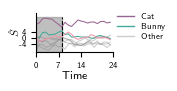

In [48]:
# plot the probabilities over time
sprite_colors = ['gray', '#44aa99', 'gray', 'gray', 'gray', 'gray', '#ee99aa', '#986491']
fig_probs = plt.figure(figsize=(1, 0.5))
ax_probs = fig_probs.add_subplot(111)
timesteps = np.arange(0, n_steps)
true_id = ground_truth['sprite_idx'][sample_to_focus].cpu().numpy()
print(f"Animal in the simulation: {sprite_names[true_id]}, Prediction during simulation: {sprite_names[most_common[0][0]]}")
for i in range(8):
    if i not in [true_id, most_common[1][0], most_common[2][0] if len(most_common) > 2 else -1]:
        alpha = 0.4
    else:
        alpha = 1
    ax_probs.plot(timesteps, ids_for_sample[:n_steps, i].cpu().numpy(), label=sprite_names[i], color=sprite_colors[i], alpha=alpha, linewidth=0.75)
min_y = ids_for_sample[:n_steps, :].min().cpu().numpy()
max_y = ids_for_sample[:n_steps, :].max().cpu().numpy()
ax_probs.vlines(8, min_y, max_y+0.5, color='black', linestyle='--', linewidth=0.75)
ax_probs.fill_betweenx([min_y, max_y+0.5], 0, 8, color='gray', alpha=0.5)
sns.despine()
ax_probs.set_xlabel('Time', fontsize=8)
ax_probs.set_ylabel(r'$\hat{S}$', fontsize=8)
# ax_probs.set_title(f"Sprite ID Probabilities for the simulated sample", fontsize=8)
ax_probs.set_ylim(min_y, max_y+3)
ax_probs.set_xlim(0, n_steps)
# Set the ticks and labels
ax_probs.set_xticks([0, 7, 14, n_steps])
ax_probs.set_xticklabels([0, 7, 14, n_steps], fontsize=6)
ax_probs.set_yticks([-4, 0, 4])
# reduce distance between ylabel and axis
ax_probs.yaxis.set_label_coords(-0.2, 0.5)
ax_probs.xaxis.set_label_coords(0.5, -0.5)
ax_probs.set_yticklabels([-4, 0, 4], fontsize=6)
# legend: all gray lines should be labeled as "Other"
legend_elements_probs = [
    Line2D([0], [0], color=sprite_colors[true_id], lw=1, label=sprite_names[true_id]),
    Line2D([0], [0], color=sprite_colors[most_common[1][0]], lw=1, label=sprite_names[most_common[1][0]]),
    # Line2D([0], [0], color=sprite_colors[most_common[2][0]], lw=1, label=sprite_names[most_common[2][0]]),
    Line2D([0], [0], color='gray', lw=1, alpha=0.4, label='Other'),
]
ax_probs.legend(handles=legend_elements_probs, fontsize=6, loc='upper right', bbox_to_anchor=(1.75, 1.2), frameon=False, labelspacing=0.3)
# fig_probs.savefig(os.path.join(sprites_savedir, 'sprite_id_probabilities.pdf'), bbox_inches='tight', dpi=300, transparent=False)

In [49]:
orientation_for_sample = pred_corrected_orientation_cts[sample_to_focus].cpu().numpy()
angle = np.arctan2(orientation_for_sample[:, 0], orientation_for_sample[:, 1])
true_angle = np.arctan2(pred_sin_true[sample_to_focus].cpu().numpy(), pred_cos_true[sample_to_focus].cpu().numpy())
true_id = ground_truth['sprite_idx'][sample_to_focus].cpu().numpy()

x_velocity_for_sample = pred_sim_predictions["x-velocity"][sample_to_focus].cpu().numpy()
y_velocity_for_sample = pred_sim_predictions["y-velocity"][sample_to_focus].cpu().numpy()
z_velocity_for_sample = pred_sim_predictions["z-velocity"][sample_to_focus].cpu().numpy()
true_x_velocity_for_sample = ground_truth["x-velocity"][sample_to_focus].cpu().numpy()
true_y_velocity_for_sample = ground_truth["y-velocity"][sample_to_focus].cpu().numpy()
true_z_velocity_for_sample = ground_truth["z-velocity"][sample_to_focus].cpu().numpy()

In [50]:
z_for_sample = pred_sim_predictions["z-position"][sample_to_focus].cpu().numpy()
true_z_for_sample = ground_truth["z-position"][sample_to_focus].cpu().numpy()

In [ ]:
def plot_id_over_time(simulated, true, ax, show_x=True, n_steps=21, legend_loc=(1.75, 1.2), show_star=False, color_idx=0):
    from collections import Counter

    timesteps = np.arange(0, n_steps)
    probs = torch.nn.functional.softmax(simulated, dim=-1)
    # topk = 2
    second_most_probable = torch.topk(probs, 2, dim=-1).indices
    # count the occurrences of each element
    flattened_tensor = second_most_probable.flatten()
    flattened_list = flattened_tensor.tolist()
    counter = Counter(flattened_list)
    # find the 3 most common elements
    most_common = counter.most_common(3)
    sprite_colors = ["gray" for _ in range(8)]
    sprite_colors[color_idx] = (0.645983, 0.384501, 0.402616, 1.0)
    for i in range(8):
        if i == true:
            alpha = 1
        else:
            alpha = 0.4
        ax.plot(timesteps, simulated[:n_steps, i].cpu().numpy(), label=sprite_names[i], color=sprite_colors[i], alpha=alpha, linewidth=1)
    min_y = simulated[:n_steps, :].min().cpu().numpy()
    max_y = simulated[:n_steps, :].max().cpu().numpy()
    ax.vlines(8, min_y, max_y+0.5, color='black', linestyle='--', linewidth=1)
    ax.fill_betweenx([min_y, max_y+0.5], 0, 8, color='gray', alpha=0.5)
    if show_star:
        ax.annotate("*", xy=(8, max_y+2), xytext=(8-0.2, max_y+2),
                fontsize=10, color="black", ha='left', va='center', fontweight='bold')
    sns.despine(ax=ax)
    ax.set_xlabel('Time', fontsize=8)
    ax.set_ylabel(r'$\hat{S}$', fontsize=8)
    ax.set_ylim(min_y, max_y+3)
    ax.set_xlim(0, n_steps)
    # Set the ticks and labels
    if show_x:
        ax.set_xticks([0, 8, 16, n_steps])
        ax.set_xticklabels([0, 8, 16, n_steps], fontsize=8)
    else:
        ax.set_xticks([])
        ax.set_xticklabels([])

    ax.set_yticks([-4, 0, 4])
    ax.set_yticklabels([-4, 0, 4], fontsize=8)
    # reduce distance between ylabel and axis
    ax.yaxis.set_label_coords(-0.15, 0.5)
    
    if legend_loc:
        legend_elements_probs = [
            Line2D([0], [0], color=sprite_colors[true], lw=1, label=sprite_names[true]),
            Line2D([0], [0], color=sprite_colors[most_common[1][0]], lw=1, label=sprite_names[most_common[1][0]]),
            Line2D([0], [0], color=sprite_colors[most_common[2][0]], lw=1, label=sprite_names[most_common[2][0]]),
            Line2D([0], [0], color='gray', lw=1, alpha=0.4, label='Other'),
        ]
        ax.legend(handles=legend_elements_probs, fontsize=6, loc=legend_loc, frameon=False, labelspacing=0.3, ncols=2, handlelength=1, columnspacing=0.5)


def plot_prediction_over_time(simulated, true, ax, y_label, show_x=True, min_y=-1, max_y=1, n_steps=21, is_angle=False, show_star=False):
    pred_color = (0.645983, 0.384501, 0.402616, 1.0)
    timesteps = np.arange(0, n_steps)
    ax.plot(timesteps, true[:n_steps], label='True', color='black', lw=1, alpha=0.8)
    ax.plot(timesteps, simulated[:n_steps], label='Simulated', color=pred_color, lw=1, alpha=0.8)
    ax.vlines(8, min_y, max_y, color='black', linestyle='--', linewidth=0.75)
    ax.fill_betweenx([min_y, max_y], 0, 8, color='gray', alpha=0.5)
    if show_star:
        ax.annotate("*", xy=(8, max_y+0.25*max_y), xytext=(8-0.2, max_y+0.25*max_y),
                fontsize=10, color="black", ha='left', va='center', fontweight='bold')
    sns.despine(ax=ax)
    ax.set_xlim(0, n_steps)
    ax.set_ylabel(y_label, fontsize=8)
    if show_x:
        ax.set_xlabel('Time', fontsize=8)
        ax.set_xticks([0, 8, 16, n_steps])
        ax.set_xticklabels([0, 8, 16, n_steps], fontsize=8)
    else:
        ax.set_xticks([])
        ax.set_xticklabels([])
    # use pi symbols for yticks
    if is_angle:
        ax.set_yticks([-np.pi, 0, np.pi])
        ax.set_yticklabels([r'$-\pi$', r'$0$', r'$\pi$'], fontsize=8)
    else:
        ax.set_yticks([-1, 0, 1])
        ax.set_yticklabels([-1, 0, 1], fontsize=8)
    ax.set_ylim(min_y, max_y+0.5*max_y)
    # reduce distance between ylabel and axis
    ax.yaxis.set_label_coords(-0.15, 0.5)


def plot_rollout(gt_x, gt_y, pred_sim_x, pred_sim_y, ax, n_steps, ctx_steps, legend_loc=(1.75, 1), inferred_only=False, legend_n_cols=2):
    ax.plot(gt_x[:n_steps], gt_y[:n_steps], '-', color="black", linewidth=1, alpha=1.0)
    ax.plot(gt_x[n_steps-1], gt_y[n_steps-1], 'o', color="black",
            markersize=3.5, alpha=1.0, label="End")
    pred_color = (0.645983, 0.384501, 0.402616, 1.0)
    if inferred_only:
        steps = ctx_steps + 1
    else:
        steps = n_steps
    ax.plot(pred_sim_x[:ctx_steps+1], pred_sim_y[:ctx_steps+1], '-', 
            color="gray", linewidth=6, alpha=0.5, solid_capstyle='round', solid_joinstyle='round')
    ax.plot(pred_sim_x[:steps], pred_sim_y[:steps], '-', color=pred_color, linewidth=1, alpha=1.0)
    if not inferred_only:
        ax.plot(pred_sim_x[n_steps-1], pred_sim_y[n_steps-1], 'o', color=pred_color,
                markersize=3.5, alpha=1.0, label="End")
    ax.set_xlim(-1.0, 1.0)
    ax.set_ylim(-1.0, 1.0)
    ax.set_aspect('equal')
    # Remove ticks and labels
    ax.set_xticks([])
    ax.set_yticks([])

    legend_elements = [
        Line2D([0], [0], linestyle='-', color="black", lw=1.2, label='True'),
        Line2D([0], [0], linestyle='-', color=pred_color, lw=1.2, label='Simulated'),
        Line2D([0], [0], linestyle='-', color="gray", lw=4, label='Inference'),
        Line2D([0], [0], marker='o', color='none', markeredgecolor='k', 
               markerfacecolor='w', markersize=3.5, linestyle='', 
               label="End"),
    ]
    # decrease border line width
    for spine in ax.spines.values():
        spine.set_linewidth(0.5)  # You can adjust this value as needed

    if legend_loc:
        ax.legend(handles=legend_elements, fontsize=6, frameon=False, labelspacing=0.3, ncols=legend_n_cols, loc=legend_loc, handlelength=1, columnspacing=0.5)

In [52]:
gt_x = ground_truth['x-position'][sample_to_focus].cpu().numpy()
gt_y = ground_truth['y-position'][sample_to_focus].cpu().numpy()
pred_sim_x = pred_sim_predictions['x-position'][sample_to_focus].cpu().numpy()
pred_sim_y = pred_sim_predictions['y-position'][sample_to_focus].cpu().numpy()

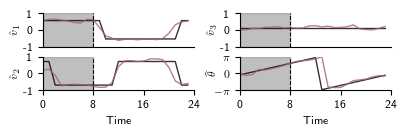

In [220]:
# latent factor estimates
from matplotlib.gridspec import GridSpec


fig = plt.figure(figsize=(4.5, 1.0))
gs = GridSpec(2, 2, figure=fig, width_ratios=[1, 1], height_ratios=[1, 1])
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])

# plot z over time
plot_prediction_over_time(x_velocity_for_sample, true_x_velocity_for_sample, ax1, r'$\hat{v}_1$', show_x=False, min_y=-1, max_y=1, n_steps=n_steps)
# plot v_x over time
plot_prediction_over_time(y_velocity_for_sample, true_y_velocity_for_sample, ax3, r'$\hat{v}_2$', show_x=True, min_y=-1, max_y=1, n_steps=n_steps)
plot_prediction_over_time(z_velocity_for_sample, true_z_velocity_for_sample, ax2, r'$\hat{v}_3$', show_x=False, min_y=-1, max_y=1, n_steps=n_steps)
# plot angle over time
plot_prediction_over_time(angle, true_angle, ax4, r'$\widehat{\theta}$', show_x=True, min_y=-np.pi, max_y=np.pi, n_steps=n_steps, is_angle=True)
# plot sprite id over time
# plot_id_over_time(ids_for_sample, true_id, ax4, show_x=True, n_steps=n_steps, legend_loc=None)
# Adjust the spacing between subplots
plt.subplots_adjust(wspace=0.3, hspace=0.3)

ax1.set_ylim(-1, 1)
ax2.set_ylim(-1, 1)
ax3.set_ylim(-1, 1)
ax4.set_ylim(-np.pi, np.pi)
# Save the figure
fig.savefig(os.path.join(sprites_savedir, 'sprite_sim_factors_noisy.pdf'), bbox_inches='tight', dpi=300, transparent=True)

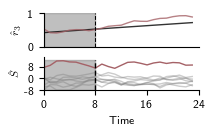

In [ ]:
# latent factor estimates
from matplotlib.gridspec import GridSpec


fig = plt.figure(figsize=(2, 1.0))
gs = GridSpec(2, 1, figure=fig, width_ratios=[1], height_ratios=[1, 1])
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])

# plot z over time
plot_prediction_over_time(z_for_sample, true_z_for_sample, ax1, r'$\hat{r}_3$', show_x=False, min_y=0, max_y=1, n_steps=n_steps)
# plot sprite id over time
plot_id_over_time(ids_for_sample, true_id, ax2, show_x=True, n_steps=n_steps, legend_loc=None, color_idx=most_common[0][0])
# Adjust the spacing between subplots
plt.subplots_adjust(wspace=0.3, hspace=0.3)

ax1.set_ylim(0, 1)
ax2.set_ylim(-5, 15)
ax2.set_yticks([-8, 0, 8])
ax2.set_yticklabels([-8, 0, 8], fontsize=8)
# Save the figure
fig.savefig(os.path.join(sprites_savedir, 'sprite_sim_id_and_scale_noisy.pdf'), bbox_inches='tight', dpi=300, transparent=True)

7 Cat


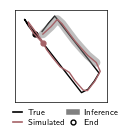

In [54]:
# 2D trajectory plot
fig, ax = plt.subplots(figsize=(1.2, 1.2))
plot_rollout(gt_x, gt_y, pred_sim_x, pred_sim_y, ax, n_steps, ctx_steps, legend_loc=(-0.05, -0.3), inferred_only=False)
fig.savefig(os.path.join(sprites_savedir, "sprite_sim_simulated_noisy.pdf"), bbox_inches='tight', dpi=300, transparent=True)
print(ground_truth['sprite_idx'][sample_to_focus].item(), sprite_names[ground_truth['sprite_idx'][sample_to_focus].item()])

Other sample sprite id: 6


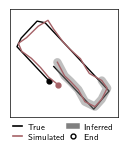

In [134]:
other_sample = 0
other_gt_x = ground_truth['x-position'][other_sample].cpu().numpy()
other_gt_y = ground_truth['y-position'][other_sample].cpu().numpy()
other_pred_sim_x = pred_sim_predictions['x-position'][other_sample].cpu().numpy()
other_pred_sim_y = pred_sim_predictions['y-position'][other_sample].cpu().numpy()
other_sprite_id = ground_truth['sprite_idx'][other_sample].cpu().numpy()
fig, ax = plt.subplots(figsize=(1.4, 1.4))
plot_rollout(other_gt_x, other_gt_y, other_pred_sim_x, other_pred_sim_y, ax, n_steps, ctx_steps, legend_loc=(0.0, -0.25), inferred_only=False)
print(f"Other sample sprite id: {other_sprite_id}")

Other sample sprite id: 0


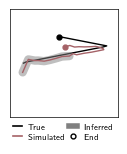

In [132]:
other_sample = 8
other_gt_x = ground_truth['x-position'][other_sample].cpu().numpy()
other_gt_y = ground_truth['y-position'][other_sample].cpu().numpy()
other_pred_sim_x = pred_sim_predictions['x-position'][other_sample].cpu().numpy()
other_pred_sim_y = pred_sim_predictions['y-position'][other_sample].cpu().numpy()
other_sprite_id = ground_truth['sprite_idx'][other_sample].cpu().numpy()
fig, ax = plt.subplots(figsize=(1.4, 1.4))
plot_rollout(other_gt_x, other_gt_y, other_pred_sim_x, other_pred_sim_y, ax, n_steps, ctx_steps, legend_loc=(0.0, -0.25), inferred_only=False)
print(f"Other sample sprite id: {other_sprite_id}")

Other sample sprite id: 5


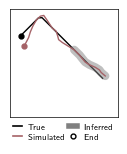

In [129]:
other_sample = 20
other_gt_x = ground_truth['x-position'][other_sample].cpu().numpy()
other_gt_y = ground_truth['y-position'][other_sample].cpu().numpy()
other_pred_sim_x = pred_sim_predictions['x-position'][other_sample].cpu().numpy()
other_pred_sim_y = pred_sim_predictions['y-position'][other_sample].cpu().numpy()
other_sprite_id = ground_truth['sprite_idx'][other_sample].cpu().numpy()
fig, ax = plt.subplots(figsize=(1.4, 1.4))
plot_rollout(other_gt_x, other_gt_y, other_pred_sim_x, other_pred_sim_y, ax, n_steps, ctx_steps, legend_loc=(0.0, -0.25), inferred_only=False)
print(f"Other sample sprite id: {other_sprite_id}")

Other sample sprite id: 7


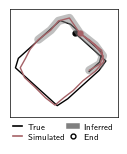

In [229]:
other_sample = 25
other_gt_x = ground_truth['x-position'][other_sample].cpu().numpy()
other_gt_y = ground_truth['y-position'][other_sample].cpu().numpy()
other_pred_sim_x = pred_sim_predictions['x-position'][other_sample].cpu().numpy()
other_pred_sim_y = pred_sim_predictions['y-position'][other_sample].cpu().numpy()
other_sprite_id = ground_truth['sprite_idx'][other_sample].cpu().numpy()
fig, ax = plt.subplots(figsize=(1.4, 1.4))
plot_rollout(other_gt_x, other_gt_y, other_pred_sim_x, other_pred_sim_y, ax, n_steps, ctx_steps, legend_loc=(0.0, -0.25), inferred_only=False)
print(f"Other sample sprite id: {other_sprite_id}")

Other sample sprite id: 1


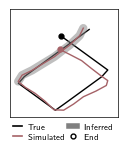

In [130]:
other_sample = 40
other_gt_x = ground_truth['x-position'][other_sample].cpu().numpy()
other_gt_y = ground_truth['y-position'][other_sample].cpu().numpy()
other_pred_sim_x = pred_sim_predictions['x-position'][other_sample].cpu().numpy()
other_pred_sim_y = pred_sim_predictions['y-position'][other_sample].cpu().numpy()
other_sprite_id = ground_truth['sprite_idx'][other_sample].cpu().numpy()
fig, ax = plt.subplots(figsize=(1.4, 1.4))
plot_rollout(other_gt_x, other_gt_y, other_pred_sim_x, other_pred_sim_y, ax, n_steps, ctx_steps, legend_loc=(0.0, -0.25), inferred_only=False)
print(f"Other sample sprite id: {other_sprite_id}")

6
0
5
7
1


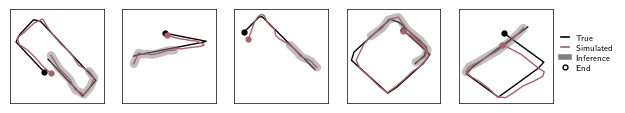

In [54]:
from matplotlib.gridspec import GridSpec


fig = plt.figure(figsize=(7, 1.4))
gs = GridSpec(1, 5, figure=fig, width_ratios=[1, 1, 1, 1, 1])

for i, smpl in enumerate([0, 8, 20, 25, 40]):
    gt_x = ground_truth['x-position'][smpl].cpu().numpy()
    gt_y = ground_truth['y-position'][smpl].cpu().numpy()
    pred_sim_x = pred_sim_predictions['x-position'][smpl].cpu().numpy()
    pred_sim_y = pred_sim_predictions['y-position'][smpl].cpu().numpy()
    sprite_id = ground_truth['sprite_idx'][smpl].cpu().numpy()
    ax = fig.add_subplot(gs[0, i])
    legend_loc = (1.05, 0.3) if i == 4 else None
    print(sprite_id)
    plot_rollout(gt_x, gt_y, pred_sim_x, pred_sim_y, ax, n_steps, ctx_steps, legend_loc=legend_loc, inferred_only=False, legend_n_cols=1)
    # ax.set_title(f"Sample {sprite_names[sprite_id].lower()} trajectory", fontsize=6)
fig.savefig(os.path.join(sprites_savedir, 'simulated_trajectory_grid.pdf'), bbox_inches='tight', dpi=300, transparent=True)